In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Проверим, что файл с данными читается
df = pd.read_csv('../data/raw/Churn.csv')
print("Успешно! Строк:", df.shape[0], "Столбцов:", df.shape[1])
df.head(3) 

Успешно! Строк: 7043 Столбцов: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [2]:
# Преобразуем TotalCharges в числовой тип (пробелы заменятся на NaN)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')

print("Информация о датасете:")
df.info()

print("\nПропущенные значения:")
missing = df.isnull().sum()
print(missing[missing > 0])

Информация о датасете:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-nul

C:\Users\User\AppData\Local\Temp\ipykernel_3180\2740036822.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='Churn', palette='Set2')


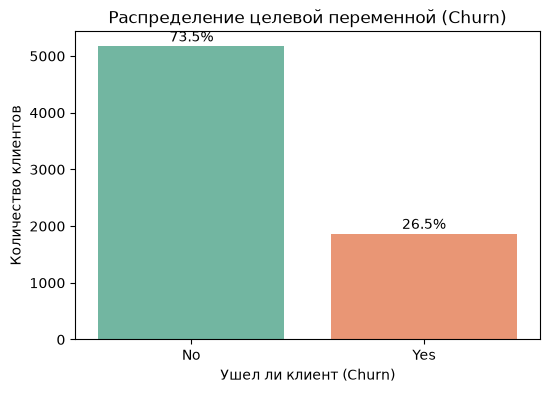

In [3]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='Churn', palette='Set2')
plt.title('Распределение целевой переменной (Churn)')
plt.xlabel('Ушел ли клиент (Churn)')
plt.ylabel('Количество клиентов')

total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%\n'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='center')

plt.show()

## Data Dictionary (Словарь данных)

| Признак (Column) | Тип данных | Описание |
| :--- | :--- | :--- |
| `customerID` | Categorical | Уникальный идентификатор клиента |
| `gender` | Categorical | Пол клиента (Male / Female) |
| `SeniorCitizen` | Binary (int) | Является ли клиент пожилым человеком (1, 0) |
| `Partner` | Categorical | Наличие партнера (Yes / No) |
| `Dependents` | Categorical | Наличие иждивенцев (Yes / No) |
| `tenure` | Numeric (int) | Количество месяцев пользования услугами |
| `PhoneService` | Categorical | Подключена ли телефонная связь (Yes / No) |
| `MultipleLines` | Categorical | Подключено ли несколько линий связи |
| `InternetService` | Categorical | Провайдер интернет-услуг (DSL, Fiber optic, No) |
| `Contract` | Categorical | Тип контракта (Month-to-month, One year, Two year) |
| `PaperlessBilling` | Categorical | Использование электронных счетов (Yes / No) |
| `PaymentMethod` | Categorical | Способ оплаты (Electronic check, Mailed check и др.) |
| `MonthlyCharges` | Numeric (float) | Ежемесячный платеж клиента |
| `TotalCharges` | Numeric (float) | Общая сумма выплат за все время |
| `Churn` | Categorical (Target) | Факт ухода клиента (Yes / No) |